# Under the hood of sea-anemone
*a walk-through of the default workflow.* 

Matthew P. Griffiths

## What happens when you upload a file?

In [1]:
import os, sys
sys.path.append('..')

usf_parent_folder = "O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/"
usf_folders = [usf_parent_folder+folder+'/' for folder in os.listdir(usf_parent_folder) if os.path.isdir(os.path.join(usf_parent_folder, folder)) and folder.startswith("USF")]

In [2]:
from temframe import TEMframe
from anemone.inversion import LogResistivity

In [3]:
df1 = TEMframe.from_usf_folder(usf_folders[0])
# df1 = TEMframe.from_usf_folder('/home/matt/geophysics_data/TEM/sTEM_data/2025_0302/USF_Files_dawa river 3/')

df3 = df1[df1['site_id'] > 0].copy()

df3.disable([0, 2])
df4 = df3.overview()

c:\Users\au646858\Documents\repositories\sea-anemone\temframe.py:168: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'P' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_data.loc[ok, 'zone_letter'] = zone_letter


In [4]:
import torch
rho = torch.ones(31)*40.
z   = torch.logspace(0, 2.1, 30)
res_start = LogResistivity.smooth(rho, z)

dbdt = df3.forward_operators[1](*res_start.mod)

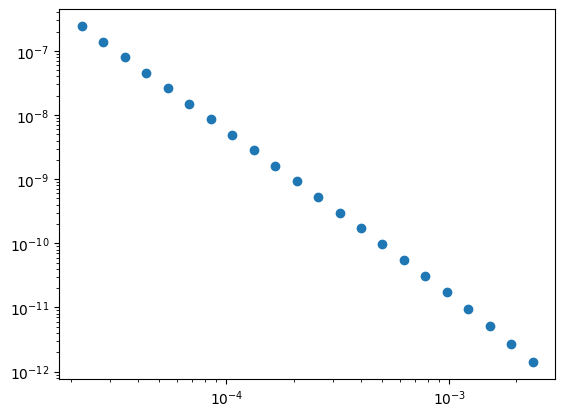

In [5]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.loglog(df3.forward_operators[1].times, 10**dbdt, 'o', label='db/dt')

In [6]:
df_layers, df4 = df3.invert(res_start)

c:\Users\au646858\Documents\repositories\sea-anemone\temframe.py:338: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_data['include'] = df_data['inuse_manual'].fillna(df_data['inuse_auto'])


damping attempts: 4
001	Data misfit:	18.82	Total misfit:	8.67
damping attempts: 2
002	Data misfit:	14.37	Total misfit:	6.64
damping attempts: 1
003	Data misfit:	11.61	Total misfit:	5.39
damping attempts: 1
004	Data misfit:	9.79	Total misfit:	4.58
damping attempts: 1
005	Data misfit:	8.42	Total misfit:	3.98
damping attempts: 1
006	Data misfit:	7.39	Total misfit:	3.53
damping attempts: 1
007	Data misfit:	6.56	Total misfit:	3.17
damping attempts: 1
008	Data misfit:	5.86	Total misfit:	2.88
damping attempts: 1
009	Data misfit:	5.28	Total misfit:	2.64
damping attempts: 1
010	Data misfit:	4.80	Total misfit:	2.45
damping attempts: 1
011	Data misfit:	4.41	Total misfit:	2.30
damping attempts: 1
012	Data misfit:	4.09	Total misfit:	2.18
damping attempts: 1
013	Data misfit:	3.82	Total misfit:	2.08
damping attempts: 1
014	Data misfit:	3.57	Total misfit:	2.00
damping attempts: 1
015	Data misfit:	3.36	Total misfit:	1.93
damping attempts: 1
016	Data misfit:	3.17	Total misfit:	1.87
damping attempts: 1
0

In [7]:
df3.history

['return cls.from_sweeps(sweeps, track_history = TEMframe.from_usf_folder("O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/USF_Files_diredawa_boren_ToLegaGoro_profiler_day6/")',
 "df3 = df1[df1['site_id'] > 0].copy()",
 'df3.disable([0, 2])']

In [8]:
#import pandas as pd
df_layers_long = df_layers.melt(id_vars=['site_id', 'daytime', 'longitude', 'latitude', 'date', 'elevation', 'layer', 'resistivity'], value_vars=['top_depth', 'bottom_depth'], var_name='depth_type', value_name='depth').sort_values(['daytime', 'layer', 'depth'])

In [9]:
import numpy as np
import plotly.express as px

# Pivot the melted DataFrame
df_layers_long['log_resistivity'] = np.log10(df_layers_long['resistivity'])

heatmap_df = df_layers_long.pivot_table(
    index='depth', columns='site_id', values='log_resistivity'
)

# Sort depth so it increases downward
heatmap_df = heatmap_df.sort_index(ascending=True)

fig = px.imshow(
    heatmap_df,
    aspect='auto',
    origin='lower',
    color_continuous_scale='turbo',
    labels={'x': 'Site ID', 'y': 'Depth [m]', 'color': 'Resistivity [Ω·m]'},
    title='Resistivity Heatmap by Site and Depth',
    zmin=heatmap_df.min().min(),
    zmax=heatmap_df.max().max(),
)

fig.update_yaxes(autorange="reversed")
fig.show()

In [10]:
df_layers_long.history

['return cls.from_sweeps(sweeps, track_history = TEMframe.from_usf_folder("O:/Nat-Tech_HGG-Projects/Projects/2025_RGRMP/Pilots/DireDawa/Data/profiler_usf/USF_Files_diredawa_boren_ToLegaGoro_profiler_day6/")',
 "df3 = df1[df1['site_id'] > 0].copy()",
 'df3.disable([0, 2])',
 'df_layers, df4 = df3.invert(res_start)',
 'return self[key]',
 "df_layers_long['log_resistivity'] = np.log10(df_layers_long['resistivity'])",
 'data = data[to_filter]']

In [11]:
from panels import Map

In [14]:
m1 = Map(df3.overview())
m1.render()